In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

In [2]:
df = pd.read_csv("testing/ATGNATAWW_counts.csv")
df.head()

,name,count,term_ratio,z_score,p_val,padj
0,cytosol,32,0.004497,-2.895881,0.003781,1.0
1,Dbf4-dependent protein kinase complex,1,0.000141,1.251598,0.210716,1.0
2,negative regulation of DNA recombination,5,0.000703,1.571698,0.116021,1.0
3,muscle attachment,1,0.000141,0.909441,0.363117,1.0
4,piecemeal microautophagy of the nucleus,1,0.000141,0.657371,0.510942,1.0


In [5]:
def plot_enriched_terms(df, alpha=0.05, cmap="viridis_r", out_path=None):
    sig = df[df["padj"] < alpha].sort_values("term_ratio")  # largest ends up on top

    # padj spans many orders of magnitude and can be exactly 0,
    # so use -log10 and clip zeros to the smallest nonzero value
    floor = sig.loc[sig["padj"] > 0, "padj"].min()
    sig = sig.assign(neglog_padj=-np.log10(sig["padj"].clip(lower=floor)))

    norm = Normalize(vmin=sig["neglog_padj"].min(), vmax=sig["neglog_padj"].max())
    colormap = plt.get_cmap(cmap)
    colors = colormap(norm(sig["neglog_padj"]))

    fig, ax = plt.subplots(figsize=(8, 0.4 * len(sig) + 1.5))
    ax.barh(sig["name"], sig["term_ratio"], color=colors)

    # barh doesn't create a colorbar, so build one from a ScalarMappable
    sm = cm.ScalarMappable(norm=norm, cmap=colormap)
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label(r"$-\log_{10}$(adjusted p-value)")

    ax.set_xlabel("Term ratio")
    fig.tight_layout()
    if out_path:
        fig.savefig(out_path, dpi=200, bbox_inches="tight")
    return fig, ax

(<Figure size 800x990 with 2 Axes>, <Axes: xlabel='Term ratio'>)

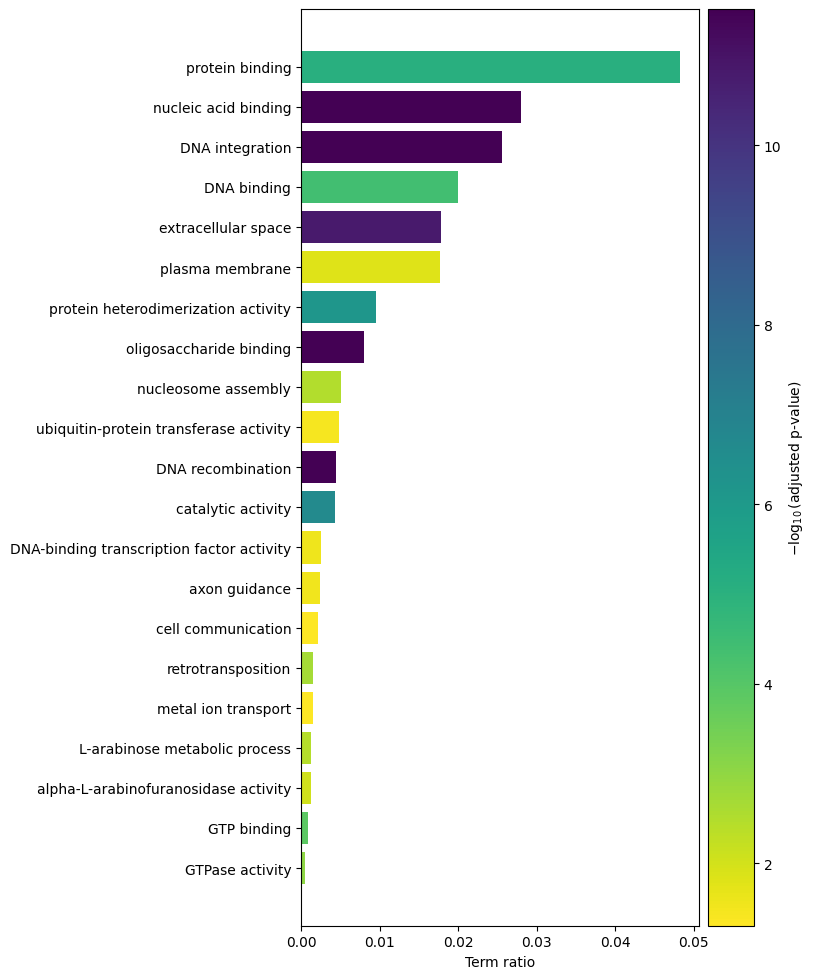

In [6]:
plot_enriched_terms(df, out_path="ATGNATAWW_plot.png")